# 02 · Forwarding graph and communities

Builds the channel forwarding graph, finds communities with Leiden, describes what they are, and measures
how much content crosses their borders. The communities are the border of **RQ1**.

**Conventions** (`docs/PROJECT_CONTEXT.md` §5, `docs/DECISIONS.md`)
- Edge direction is content flow, **`src_id -> dest_id`**: written in `src`, reposted in `dest`.
  Out-strength = how often a channel was reposted; in-strength = how much it reposted.
- Weight = number of forwards. Forwards with a hidden sender, a source outside the dataset, or
  `src = dest` are dropped.
- Leiden: `RBConfigurationVertexPartition`, resolution 1.0, directed, weighted, seed 42, run until
  convergence (D1).

**Saved:** `tgdata/derived/edges_full.parquet`, `edges_en.parquet`, `communities.parquet` (+ meta);
`results/02/`: 6 figures (PNG) and 4 key tables (graph summary, baseline crossing, community conspiracy
shares, conspiracy blocks).

Robustness of the communities: notebook 02c. Backbones: 02b. Bow-tie: 02d.

In [1]:
import json, sys, time
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, graph, plots
from tgperm.describe import mix, composition, impurity_summary, blocks, purity, purity_null

plots.use_style()
OUT = cfg.RESULTS / "02"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80, "display.width", 200)

con = data.connect()
channels = data.channel_table(con)
cons_of = channels.set_index("channel_id").conspiracy
print(f"channels: {len(channels):,}; English: {(channels.language == 'en').sum():,}; "
      f"conspiracy: {channels.conspiracy.sum():,}; Sabmyk: {channels.sabmyk.sum():,}")

channels: 120,979; English: 19,768; conspiracy: 11,618; Sabmyk: 236


## 1 · Edge tables

One DuckDB query aggregates the 93.4M forwards into one row per `(src_id, dest_id)`; the English–English
table is a filter of it. Files are reused if present (`overwrite=True` rebuilds). Counts are checked
against the extraction (`PROJECT_CONTEXT.md` §4.2).

In [2]:
paths = data.build_edges(con)
edges = pd.read_parquet(paths["full"])
edges_en = pd.read_parquet(paths["en"])

def counts(e):
    return len(np.union1d(e.src_id, e.dest_id)), len(e), int(e.weight.sum())

assert counts(edges) == (120_715, 4_676_642, 57_947_677), counts(edges)
assert counts(edges_en) == (18_216, 785_846, 13_166_079), counts(edges_en)
for name, e in [("full", edges), ("English–English", edges_en)]:
    n, m, w = counts(e)
    print(f"{name:>16}: {n:,} channels, {m:,} edges, {w:,} forwards ({e.n_text.sum():,} text, {e.n_media.sum():,} media)")

            full: 120,715 channels, 4,676,642 edges, 57,947,677 forwards (34,302,930 text, 23,644,747 media)
 English–English: 18,216 channels, 785,846 edges, 13,166,079 forwards (7,731,006 text, 5,435,073 media)


## 2 · What the graph looks like

Reciprocity per edge (reverse edge exists) and per forward (`Σ min(w_ij, w_ji) / Σ w_ij`).

In [3]:
g = graph.to_igraph(edges)
g_en = graph.to_igraph(edges_en)
summary = pd.DataFrame({"full": graph.graph_summary(edges, g), "english_english": graph.graph_summary(edges_en, g_en)})
summary.to_csv(OUT / "02_graph_summary.csv")
summary.style.format(lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.4f}")

,full,english_english
nodes,"120,715","18,216"
edges,"4,676,642","785,846"
forwards,"57,947,677","13,166,079"
text_forwards_share,0.5920,0.5872
density,0.0003,0.0024
mean_out_degree,38.7412,43.1404
reciprocity_edges,0.1863,0.1479
reciprocity_weighted,0.1196,0.0990
wcc_count,5.0000,59.0000
largest_wcc_share,0.9999,0.9918


In [4]:
nodes = graph.node_table(edges)
nodes_en = graph.node_table(edges_en)
conc = pd.DataFrame({"full": graph.top_share(nodes.out_strength.to_numpy()),
                     "english_english": graph.top_share(nodes_en.out_strength.to_numpy())}).rename(index=lambda f: f"top {f:.0%} of channels")
print("Share of forwards whose source is among the top x% of channels by times reposted:")
conc.style.format("{:.1%}")

Share of forwards whose source is among the top x% of channels by times reposted:


,full,english_english
top 1% of channels,42.9%,40.2%
top 5% of channels,70.1%,70.0%
top 10% of channels,82.2%,82.4%


In [5]:
info = channels.set_index("channel_id")[["username", "language", "ch_topic", "conspiracy", "n_subscribers"]]
(nodes.nlargest(10, "out_strength").set_index("channel_id").join(info)
 [["username", "language", "ch_topic", "conspiracy", "out_strength", "out_degree"]]
 .rename(columns={"out_strength": "times_reposted", "out_degree": "reposted_by"}))

,username,language,ch_topic,conspiracy,times_reposted,reposted_by
channel_id,,,,,,
1139528163,shmirziyoyev,ru,NaN,False,477192,2705
1296087183,mafia_7ru,ru,NaN,False,386443,1034
1353291112,porno_politika,ru,NaN,False,226919,1014
1179270258,disclosetv,en,World news,False,200295,4402
1394050290,bbbreaking,ru,NaN,False,190115,6203
1305795976,TheBL1,en,US news,False,177794,462
1479163323,TommyRobinsonNews,en,US news,True,173781,3828
1303844417,sol_cremly,ru,NaN,False,171043,976
1285160972,QlobalChange,de,NaN,True,166240,1879


## 3 · Leiden communities

Directed weighted modularity is the main figure; the undirected value is for comparison with TGDataset's
0.78 (D4). Communities are numbered by size, 0 = largest (D3).

In [6]:
membership, meta = graph.leiden(g)
comm = pd.DataFrame({"channel_id": np.asarray(g.vs["channel_id"], dtype="int64"), "community": membership.astype("int32")})
comm.to_parquet(cfg.DERIVED / "communities.parquet", index=False)
(cfg.DERIVED / "communities_meta.json").write_text(json.dumps(meta, indent=2))
c_of = comm.set_index("channel_id").community
sizes = comm.community.value_counts().sort_index()
TOP = 15
print(f"{meta['n_communities']} communities; directed modularity {meta['modularity_directed']:.3f} "
      f"(undirected {meta['modularity_undirected']:.3f}); seed {meta['seed']}, {meta['seconds']:.0f} s")
print(f"the {TOP} largest hold {sizes.iloc[:TOP].sum() / len(comm):.1%} of channels; "
      f"{(sizes >= 100).sum()} communities have ≥ 100 channels")
ch = comm.merge(nodes, on="channel_id").merge(channels, on="channel_id", how="left")

289 communities; directed modularity 0.862 (undirected 0.862); seed 42, 130 s
the 15 largest hold 89.4% of channels; 34 communities have ≥ 100 channels


## 4 · What the communities are

A community is described by its languages and by its **most reposted channels**, not by the dataset's LDA
channel topics: those exist only for English channels and mislead for some communities (C4's meme
channels are labeled "Religion"; C6 is far-right/conspiracy). Themes below are read from these lists.

In [7]:
for c in range(TOP):
    m = ch[ch.community == c]
    top = m.nlargest(6, "out_strength")
    print(f"C{c} ({len(m):,} ch.; {mix(m.language)}): " + " | ".join(str(t)[:30] for t in top.title.fillna(top.username)))

C0 (21,885 ch.; ru 94%, unknown 4%, en 1%): Раньше всех. Ну почти. | РИА Новости | Пул N3 | RT на русском | Mash | НЕЗЫГАРЬ
C1 (20,504 ch.; ru 68%, unknown 24%, en 4%): Двач | Golden Chihuahua | Мальцовская Галерея | Интересно не будет | r/ретранслятор | Мемошная «У Лиса»
C2 (16,822 ch.; fa 94%, unknown 4%, en 1%): ایسنا | خبرگزاری فارس | خبرگزاری تسنیم | کانال نسیم‌ آنلاین | فرتاک ورزشی | عصرایران 😷 ماسک بزنیم
C3 (9,258 ch.; unknown 69%, ru 14%, bg 10%): Shavkat Mirziyoyev_press-servi | Times.uz | Edu.uz | Kun.uz | Расмий канал | Расмий хабарлар I Официальные  | MTRK ǀ Rasmiy kanal
C4 (6,386 ch.; en 35%, unknown 34%, it 22%): eternal cringe | 🎂 AnimeBirthdays | Political memes | Shitpost | shitposting.io | Syndiegram | ｚｉｏ ｔｏｎｉｎｏ ｐｏｓｔｉｎｇ
C5 (5,674 ch.; de 86%, unknown 9%, en 4%): Qlobal-Change 🇩🇪🇦🇹🇨🇭🇱🇮 🤝 🇳🇱 | 🚨Unzensiert🚨 | fuf media - Freiheit denken | ThanQ Q 2Q22 🍊 | Eva Herman Offiziell | #freejanich Oliver Janich öffe
C6 (5,067 ch.; en 78%, unknown 13%, es 2%): White Awakening ᛉ 

**Figure 1.** The 15 largest communities (89% of channels): language mix (dataset labels; "no label" =
unknown), theme read from the top channels above, size, and share of conspiracy-labeled channels
(orange: ≥ 30%).

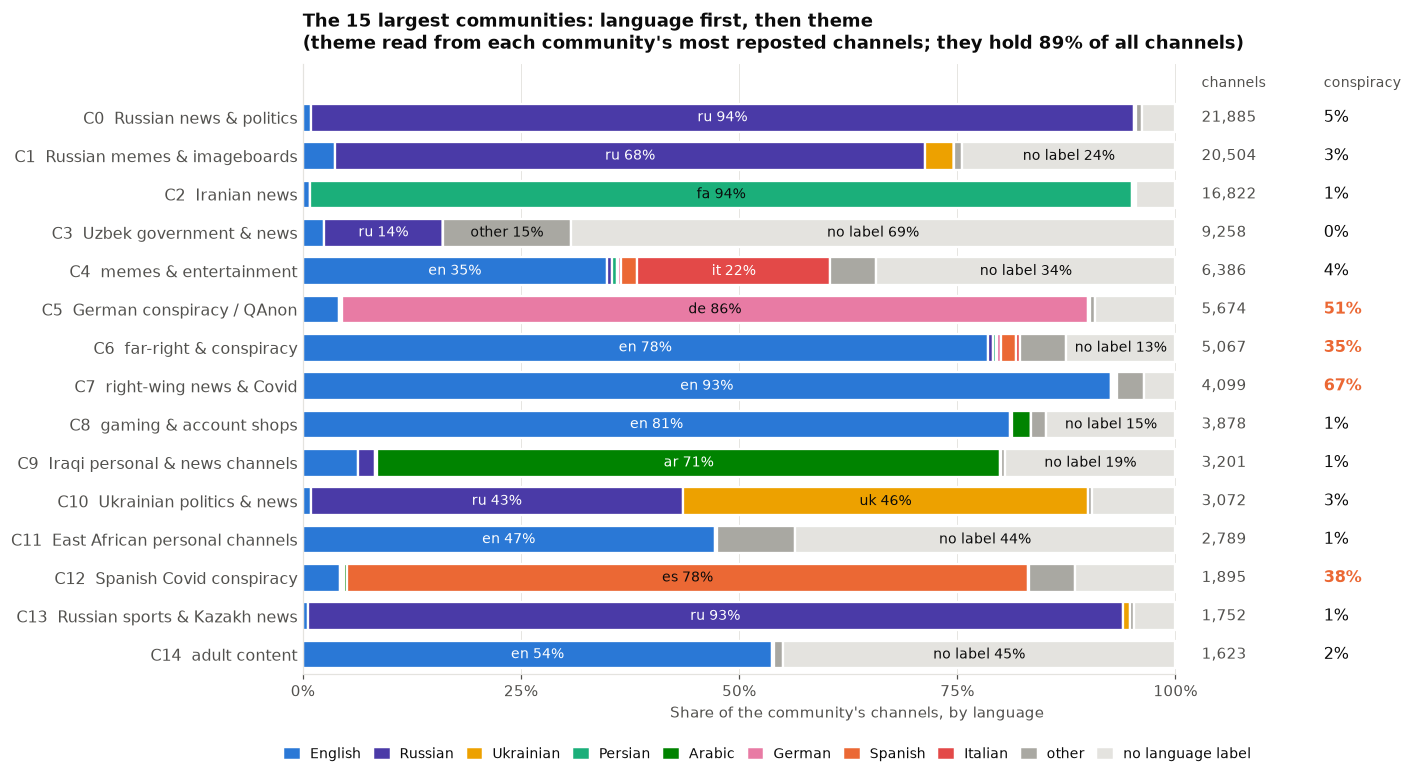

In [8]:
THEME = {0: "Russian news & politics", 1: "Russian memes & imageboards", 2: "Iranian news",
         3: "Uzbek government & news", 4: "memes & entertainment", 5: "German conspiracy / QAnon",
         6: "far-right & conspiracy", 7: "right-wing news & Covid", 8: "gaming & account shops",
         9: "Iraqi personal & news channels", 10: "Ukrainian politics & news", 11: "East African personal channels",
         12: "Spanish Covid conspiracy", 13: "Russian sports & Kazakh news", 14: "adult content"}
LANGS = [("en", "English", plots.SERIES[0]), ("ru", "Russian", plots.SERIES[6]), ("uk", "Ukrainian", plots.SERIES[3]),
         ("fa", "Persian", plots.SERIES[2]), ("ar", "Arabic", plots.SERIES[5]), ("de", "German", plots.SERIES[4]),
         ("es", "Spanish", plots.SERIES[1]), ("it", "Italian", plots.SERIES[7])]
OTHER_C, UNK_C = "#a9a8a2", "#e4e3df"
rows = []
for c in range(TOP):
    m = ch[ch.community == c]
    lang = m.language.fillna("unknown").value_counts(normalize=True)
    r = {k: lang.get(k, 0.0) for k, _, _ in LANGS}
    r["unknown"] = lang.get("unknown", 0.0)
    r["other"] = 1 - sum(r.values())
    r.update(community=c, channels=len(m), conspiracy=m.conspiracy.mean())
    rows.append(r)
L = pd.DataFrame(rows).set_index("community")

fig, ax = plt.subplots(figsize=(13, 7.2))
for i, c in enumerate(L.index):
    x0 = 0.0
    for k, name, col in LANGS + [("other", "other", OTHER_C), ("unknown", "no label", UNK_C)]:
        v = L.loc[c, k]
        if v <= 0:
            continue
        ax.barh(i, v, left=x0, height=0.72, color=col, edgecolor="white", linewidth=1.5)
        if v >= 0.12:
            dark = col in (plots.SERIES[0], plots.SERIES[6], plots.SERIES[5], plots.SERIES[7])
            ax.text(x0 + v / 2, i, f"{k if k != 'unknown' else 'no label'} {v:.0%}", ha="center", va="center",
                    fontsize=9, color="white" if dark else plots.INK)
        x0 += v
    p = L.loc[c, "conspiracy"]
    ax.text(1.03, i, f"{L.loc[c, 'channels']:,}", ha="left", va="center", fontsize=10, color=plots.INK_2)
    ax.text(1.17, i, f"{p:.0%}", ha="left", va="center", fontsize=10.5,
            color=plots.SERIES[1] if p >= 0.30 else plots.INK, fontweight="bold" if p >= 0.30 else "normal")
ax.text(1.03, -0.9, "channels", ha="left", va="center", fontsize=9, color=plots.INK_2)
ax.text(1.17, -0.9, "conspiracy", ha="left", va="center", fontsize=9, color=plots.INK_2)
ax.set_yticks(range(TOP), [f"C{c}  {THEME[c]}" for c in L.index], fontsize=10.5)
ax.invert_yaxis(); ax.set_xlim(0, 1.27); ax.set_ylim(TOP - 0.5, -1.4)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
ax.spines["bottom"].set_bounds(0, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for _, _, col in LANGS] + [plt.Rectangle((0, 0), 1, 1, color=OTHER_C),
           plt.Rectangle((0, 0), 1, 1, color=UNK_C)]
ax.legend(handles, [n for _, n, _ in LANGS] + ["other", "no language label"], loc="upper center",
          bbox_to_anchor=(0.42, -0.1), ncol=10, fontsize=9, handlelength=1, columnspacing=1)
ax.set_xlabel("Share of the community's channels, by language")
ax.set_title("The 15 largest communities: language first, then theme\n(theme read from each community's most "
             "reposted channels; they hold 89% of all channels)", loc="left", fontsize=12, pad=10)
plots.savefig(fig, "02_fig1_communities_language_theme", OUT)
plt.show()

**Sanity check:** Imperati et al. find the Sabmyk network as one community.

In [9]:
sab = ch[ch.sabmyk].community.value_counts()
print(f"Sabmyk: {sab.iloc[0]} of {sab.sum()} channels in C{sab.index[0]}, "
      f"which is {sab.iloc[0] / sizes[sab.index[0]]:.0%} Sabmyk")

Sabmyk: 234 of 236 channels in C29, which is 100% Sabmyk


## 5 · Conspiracy channels and channel topics across communities

**Figure 2.** Share of conspiracy-labeled channels per community (≥ 100 channels). They concentrate in a
few communities that match Imperati et al. (English, German, Neo-Latin, Sabmyk).

conspiracy channels in the graph: 11,615 (9.6%); communities remove 35% of the label's Gini impurity; 51% of conspiracy channels are in majority-conspiracy communities


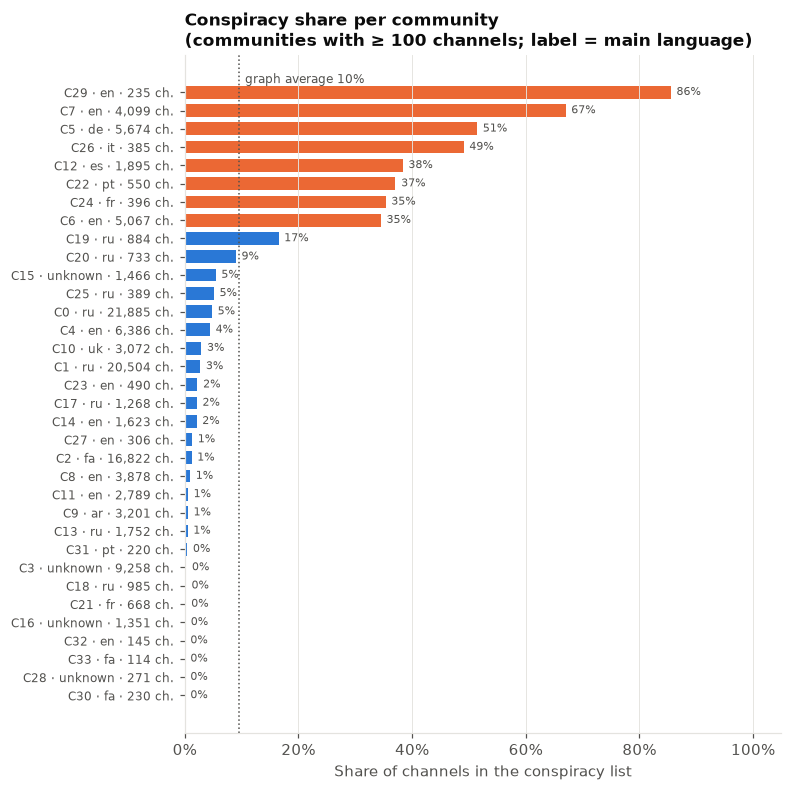

In [10]:
comp = composition(ch)
comp.to_csv(OUT / "02_community_conspiracy.csv")
imp = impurity_summary(ch, comp)
print(f"conspiracy channels in the graph: {imp['conspiracy_channels']:,} ({imp['conspiracy_share']:.1%}); "
      f"communities remove {imp['impurity_reduction']:.0%} of the label's Gini impurity; "
      f"{imp['consp_in_majority_consp_communities']:.0%} of conspiracy channels are in majority-conspiracy communities")

big = comp[comp.channels >= 100].sort_values("conspiracy_share")
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(range(len(big)), big.conspiracy_share, color=[plots.SERIES[1] if v >= 0.30 else plots.SERIES[0] for v in big.conspiracy_share], height=0.7)
ax.set_yticks(range(len(big)), [f"C{c} · {l.split(' ')[0]} · {n:,} ch." for c, l, n in zip(big.index, big.languages, big.channels)], fontsize=8)
for i, v in enumerate(big.conspiracy_share):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=7, color=plots.INK_2)
ax.axvline(ch.conspiracy.mean(), color=plots.INK_2, ls=":", lw=1)
ax.text(ch.conspiracy.mean() + 0.01, len(big) - 0.5, f"graph average {ch.conspiracy.mean():.0%}", fontsize=8, color=plots.INK_2)
ax.set_xlim(0, 1.05); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of channels in the conspiracy list")
ax.set_title("Conspiracy share per community\n(communities with ≥ 100 channels; label = main language)", loc="left")
plots.savefig(fig, "02_fig2_conspiracy_share", OUT)
plt.show()

**Figure 3.** Channel-topic purity of communities (D16): share of a community's English channels in its
main channel topic, against a null with topics shuffled across English channels (1,000 permutations,
seed 42). Communities are partly thematic, so RQ1 is not true by construction.

overall purity 0.499 vs. null 0.242; NMI(communities, channel topics) = 0.400


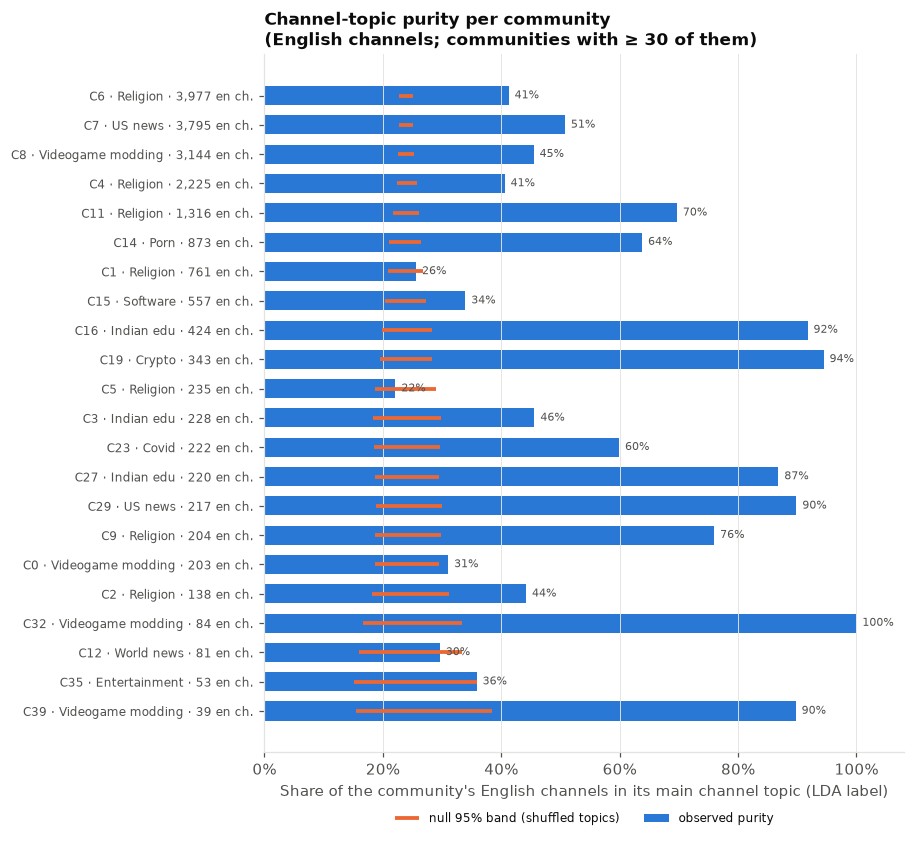

In [11]:
en_ch = ch[ch.language == "en"].reset_index(drop=True)
topics = np.array(sorted(en_ch.ch_topic.unique()))
t_code = pd.Categorical(en_ch.ch_topic, categories=topics).codes.astype(np.int64)
c_code, c_vals = pd.factorize(en_ch.community)
ov, per, main_t = purity(c_code, t_code)
null_ov, null_per = purity_null(c_code, t_code, B=1000, seed=cfg.SEED)
pur = pd.DataFrame({"community": c_vals, "english_channels": np.bincount(c_code), "main_topic": topics[main_t], "purity": per,
                    "null_low": np.quantile(null_per, 0.025, axis=0), "null_high": np.quantile(null_per, 0.975, axis=0)}
                   ).set_index("community").sort_values("english_channels", ascending=False)
shown = pur[pur.english_channels >= 30]
print(f"overall purity {ov:.3f} vs. null {null_ov.mean():.3f}; NMI(communities, channel topics) = "
      f"{ig.compare_communities(c_code.tolist(), t_code.tolist(), method='nmi'):.3f}")

s = shown.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(s) + 1.2))
y = np.arange(len(s))
ax.barh(y, s.purity, color=plots.SERIES[0], height=0.65, label="observed purity")
ax.hlines(y, s.null_low, s.null_high, color=plots.SERIES[1], lw=2.5, zorder=3, label="null 95% band (shuffled topics)")
for yi, v in zip(y, s.purity):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=7, color=plots.INK_2)
ax.set_yticks(y, [f"C{c} · {t} · {n:,} en ch." for c, t, n in zip(s.index, s.main_topic, s.english_channels)], fontsize=8)
ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the community's English channels in its main channel topic (LDA label)")
ax.set_title("Channel-topic purity per community\n(English channels; communities with ≥ 30 of them)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8)
plots.savefig(fig, "02_fig3_topic_purity", OUT)
plt.show()

## 6 · How much crosses community borders, and where it goes

The share of forwards whose source and destination are in different communities. The English–English
**text** row is the baseline RQ1 compares topics against.

In [12]:
def crossing(e, col="weight"):
    cross = e.src_id.map(c_of).to_numpy() != e.dest_id.map(c_of).to_numpy()
    v = e[col].to_numpy()
    return {"forwards": int(v.sum()), "crossing_forwards": int(v[cross].sum()), "crossing_share": v[cross].sum() / v.sum(),
            "edges": int((v > 0).sum()), "crossing_edge_share": cross[v > 0].mean()}

base = pd.DataFrame({"full, all forwards": crossing(edges), "English–English, all forwards": crossing(edges_en),
                     "English–English, text forwards": crossing(edges_en, "n_text")}).T
base.to_csv(OUT / "02_baseline_crossing.csv")
base.style.format({"forwards": "{:,.0f}", "crossing_forwards": "{:,.0f}", "edges": "{:,.0f}",
                   "crossing_share": "{:.1%}", "crossing_edge_share": "{:.1%}"})

,forwards,crossing_forwards,crossing_share,edges,crossing_edge_share
"full, all forwards","57,947,677","3,459,111",6.0%,"4,676,642",12.5%
"English–English, all forwards","13,166,079","680,739",5.2%,"785,846",13.2%
"English–English, text forwards","7,731,006","386,975",5.0%,"711,022",12.7%


**Figure 4.** Where each community's crossing content goes. Row = community where it was written; cell
(i, j) = share of i's **cross-community** English text forwards reposted in j (rows sum to 100%; the
diagonal is empty). Red = destination is conspiracy-heavy (≥ 30% conspiracy channels), blue = not, grey =
all other communities pooled. Right: share of i's forwards that leave i, and how many. Communities: the 10
with the largest English crossing volume. Edges `src -> dest`.

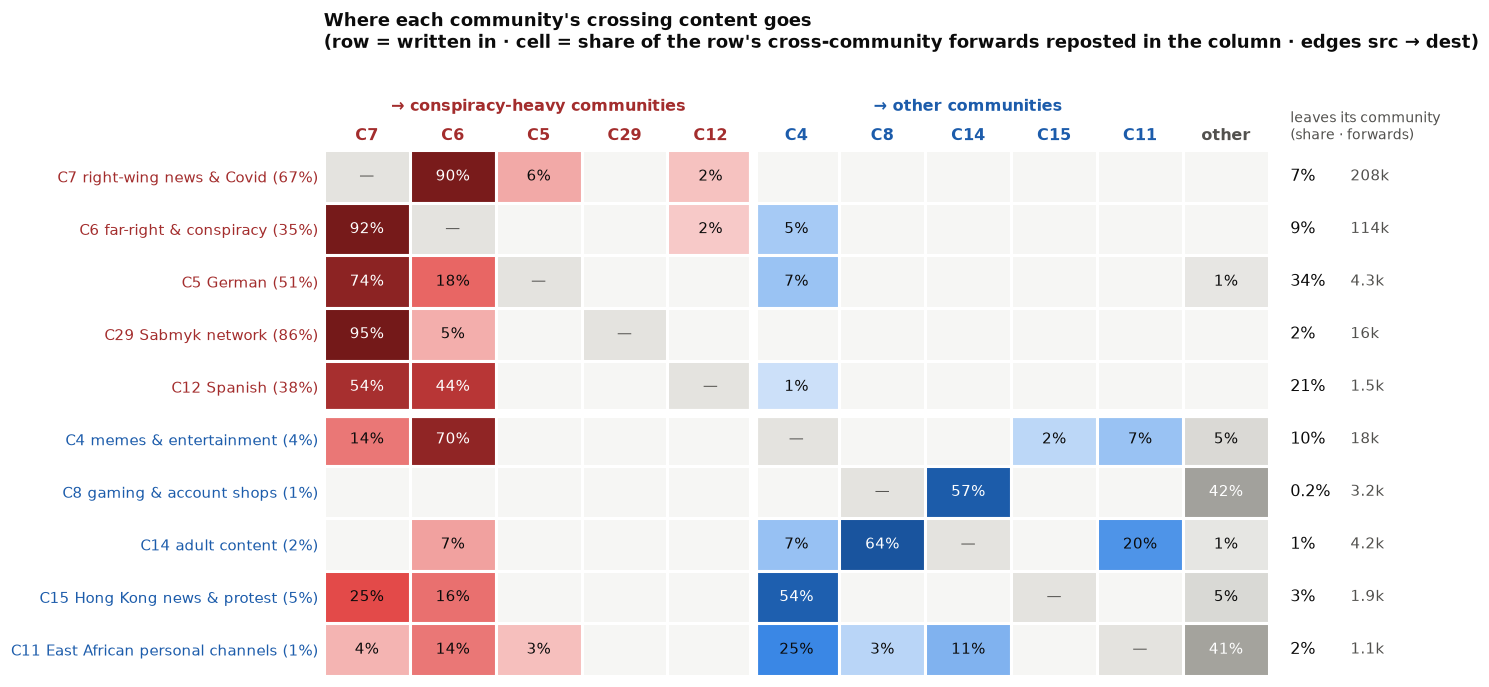

In [13]:
txt = edges_en[edges_en.n_text > 0].assign(s=lambda d: d.src_id.map(c_of), d=lambda d: d.dest_id.map(c_of))
cross = txt[txt.s != txt.d]
level = np.where(comp.conspiracy_share >= 0.30, "high", "low")
level = pd.Series(level, index=comp.index)
xvol = cross.groupby("s").n_text.sum().add(cross.groupby("d").n_text.sum(), fill_value=0).sort_values(ascending=False)
sel = xvol.index[:10].tolist()
NAMES = {**THEME, 29: "Sabmyk network", 5: "German", 12: "Spanish", 15: "Hong Kong news & protest",
         11: "East African personal channels"}
assert all(c in NAMES for c in sel), [c for c in sel if c not in NAMES]
high = sorted([c for c in sel if level[c] == "high"], key=lambda c: -xvol[c])
low = sorted([c for c in sel if level[c] != "high"], key=lambda c: -xvol[c])
order = high + low
cols = order + ["other"]
cx = cross.assign(a=cross.s.where(cross.s.isin(order), "other"), b=cross.d.where(cross.d.isin(order), "other"))
M = (cx[cx.a.isin(order)].pivot_table(index="a", columns="b", values="n_text", aggfunc="sum", fill_value=0)
     .reindex(index=order, columns=cols, fill_value=0))
S = M.div(M.sum(axis=1), axis=0)
leaves = M.sum(axis=1) / txt.groupby("s").n_text.sum().reindex(order)

REDS = LinearSegmentedColormap.from_list("reds", ["#fdeceb", "#f2a7a5", "#e34948", "#a32d2d", "#6e1717"])
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
GREYS = LinearSegmentedColormap.from_list("greys", ["#f4f4f2", "#b9b8b2", "#6e6d68"])
norm = PowerNorm(gamma=0.5, vmin=0, vmax=1)
RED, BLUE = "#a32d2d", "#1c5cab"
n, m = len(order), len(cols)
fig, ax = plt.subplots(figsize=(13, 7.2))
for i, r in enumerate(order):
    for j, c in enumerate(cols):
        if r == c:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fc="#e4e3df", ec="white", lw=2))
            ax.text(j + 0.5, i + 0.5, "—", ha="center", va="center", color=plots.INK_2, fontsize=10)
            continue
        v = S.iat[i, j]
        cmap = GREYS if c == "other" else (REDS if level[c] == "high" else BLUES)
        ax.add_patch(plt.Rectangle((j, i), 1, 1, fc="#f6f6f4" if v < 0.01 else cmap(norm(v)), ec="white", lw=2))
        if v >= 0.01:
            ax.text(j + 0.5, i + 0.5, f"{v:.0%}", ha="center", va="center", fontsize=10, color="white" if norm(v) > 0.55 else plots.INK)
    lv, nout = leaves.iat[i], int(M.iloc[i].sum())
    ax.text(m + 0.25, i + 0.5, f"{lv:.0%}" if lv >= 0.01 else f"{lv:.1%}", ha="left", va="center", fontsize=10.5, color=plots.INK)
    ax.text(m + 0.95, i + 0.5, f"{nout / 1000:,.0f}k" if nout >= 10_000 else f"{nout / 1000:,.1f}k", ha="left", va="center",
            fontsize=9.5, color=plots.INK_2)
ax.text(m + 0.25, -0.12, "leaves its community\n(share · forwards)", ha="left", va="bottom", fontsize=9, color=plots.INK_2)
ax.set_xlim(0, m + 1.9); ax.set_ylim(n, -1.6)
ax.set_yticks(np.arange(n) + 0.5, [f"C{c} {NAMES[c]} ({comp.loc[c, 'conspiracy_share']:.0%})" for c in order], fontsize=10)
for t, c in zip(ax.get_yticklabels(), order):
    t.set_color(RED if level[c] == "high" else BLUE)
for j, c in enumerate(cols):
    ax.text(j + 0.5, -0.12, f"C{c}" if c != "other" else "other", ha="center", va="bottom", fontsize=10.5, fontweight="bold",
            color=plots.INK_2 if c == "other" else (RED if level[c] == "high" else BLUE))
ax.text(len(high) / 2, -0.75, "→ conspiracy-heavy communities", ha="center", fontsize=10.5, color=RED, fontweight="bold")
ax.text(len(high) + len(low) / 2, -0.75, "→ other communities", ha="center", fontsize=10.5, color=BLUE, fontweight="bold")
ax.axhline(len(high), color="white", lw=6); ax.axvline(len(high), color="white", lw=6)
ax.set_xticks([]); ax.tick_params(axis="y", length=0); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Where each community's crossing content goes\n(row = written in · cell = share of the row's "
             "cross-community forwards reposted in the column · edges src → dest)", loc="left", fontsize=11.5, pad=12)
plots.savefig(fig, "02_fig4_crossing_heatmap", OUT)
plt.show()

## 7 · Conspiracy × community: the four blocks

Each English text forward is classified by the conspiracy label of its source and destination (C→C,
C→N, N→C, N→N), for all forwards, those that stay inside a community, and those that cross (D11).

In [14]:
t = blocks(edges_en, "n_text", c_of, cons_of)
pd.concat({("English–English text", "forwards"): t, ("full graph, all", "forwards"): blocks(edges, "weight", c_of, cons_of)},
          names=["scope", "unit", "subset"]).to_csv(OUT / "02_conspiracy_blocks.csv")
for subset in ["all", "within community", "across communities"]:
    r = t.loc[subset]
    print(f"{subset:>20}: conspiracy → non-conspiracy {r['C→N'] / (r['C→C'] + r['C→N']):.1%} of {r['C→C'] + r['C→N']:,} "
          f"conspiracy-sourced; non-conspiracy → conspiracy {r['N→C'] / (r['N→C'] + r['N→N']):.1%}")
x = t.loc["across communities"]
print(f"crossing forwards involving a conspiracy channel: {1 - x['N→N'] / x.sum():.1%} of {x.sum():,}")

# Is the asymmetry just size? Conspiracy channels repost most of all forwards; compare each rate with the
# share it would have if destinations were drawn in proportion to how much each group reposts.
a = t.loc["all"]; N = a.sum()
dest_c, dest_n = (a["C→C"] + a["N→C"]) / N, (a["C→N"] + a["N→N"]) / N
r_in, r_out = a["N→C"] / (a["N→C"] + a["N→N"]), a["C→N"] / (a["C→C"] + a["C→N"])
print(f"in: {r_in:.1%} vs {dest_c:.1%} under random mixing = {r_in / dest_c:.2f}; "
      f"out: {r_out:.1%} vs {dest_n:.1%} = {r_out / dest_n:.2f}; absolute in/out = {a['N→C'] / a['C→N']:.1f}×")

                 all: conspiracy → non-conspiracy 5.2% of 4,276,894 conspiracy-sourced; non-conspiracy → conspiracy 29.2%
    within community: conspiracy → non-conspiracy 5.3% of 3,995,445 conspiracy-sourced; non-conspiracy → conspiracy 27.7%
  across communities: conspiracy → non-conspiracy 3.3% of 281,449 conspiracy-sourced; non-conspiracy → conspiracy 77.2%
crossing forwards involving a conspiracy channel: 93.8% of 386,975
in: 29.2% vs 65.5% under random mixing = 0.45; out: 5.2% vs 34.5% = 0.15; absolute in/out = 4.6×


**Figure 5.** English–English text forwards by conspiracy label of source (rows) and destination
(columns); share of each panel's forwards. The "29% in vs. 5.2% out" comes from the **all** panel, read by
row. Edges `src -> dest`.

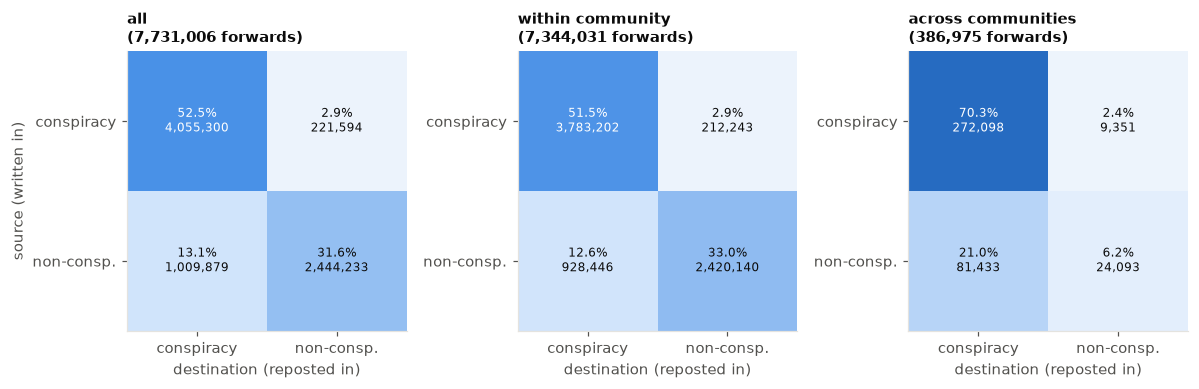

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, subset in zip(axes, ["all", "within community", "across communities"]):
    r = t.loc[subset]
    mat = np.array([[r["C→C"], r["C→N"]], [r["N→C"], r["N→N"]]])
    sh = mat / mat.sum()
    ax.imshow(sh, cmap=plots.blues_cmap(), vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{sh[i, j]:.1%}\n{mat[i, j]:,}", ha="center", va="center", fontsize=8, color="white" if sh[i, j] > 0.5 else plots.INK)
    ax.set_xticks([0, 1], ["conspiracy", "non-consp."]); ax.set_yticks([0, 1], ["conspiracy", "non-consp."])
    ax.grid(False); ax.set_xlabel("destination (reposted in)")
    ax.set_title(f"{subset}\n({mat.sum():,} forwards)", loc="left", fontsize=10)
axes[0].set_ylabel("source (written in)")
fig.tight_layout()
plots.savefig(fig, "02_fig5_conspiracy_blocks", OUT)
plt.show()

## 8 · How concentrated are the crossings?

Why the intervals in notebook 03 resample **channels**: a few sources carry many crossings (D12).

In [16]:
cross_en = edges_en.src_id.map(c_of).to_numpy() != edges_en.dest_id.map(c_of).to_numpy()
xe = edges_en[cross_en & (edges_en.n_text > 0)]
by_src = xe.groupby("src_id").n_text.sum().sort_values(ascending=False)
tot = by_src.sum()
k1 = max(1, round(0.01 * len(by_src)))
rest = ~edges_en.src_id.isin(by_src.index[:10]).to_numpy()
print(f"{tot:,} crossing English text forwards from {len(by_src):,} sources; the top 1% ({k1} channels) carry {by_src.iloc[:k1].sum() / tot:.1%}")
print(f"crossing rate {tot / edges_en.n_text.sum():.2%}; without the 10 largest crossing sources: "
      f"{edges_en.n_text.to_numpy()[rest & cross_en].sum() / edges_en.n_text.to_numpy()[rest].sum():.2%}")

386,975 crossing English text forwards from 5,763 sources; the top 1% (58 channels) carry 48.3%
crossing rate 5.01%; without the 10 largest crossing sources: 3.99%
